In [1]:
!pip install pyDOE

  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18171 sha256=99c91a4306a7fad95c5464f94ed24eb89f7504041249dcfcbcd4037d6243910b
  Stored in directory: /root/.cache/pip/wheels/ce/b6/d7/c6b64746dba6433c593e471e0ac3acf4f36040456d1d160d17
Successfully built pyDOE


In [2]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax
import copy
from typing import Callable

from functools import partial

import tensorflow as tf
from pyDOE import lhs
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import odeint

from jax import config
config.update("jax_enable_x64", True)

In [3]:
# Boundaries of the computational domain
t0, tfinal = 0.0, 1.0

In [4]:
# Define the normalization layer
class Normalize(nn.Module):
  xmin: float
  xmax: float

  @nn.compact
  def __call__(self, x):
    return 2.0*(x-self.xmin)/(self.xmax - self.xmin) - 1.0

In [5]:
class CombineBranches(nn.Module):
  @nn.compact
  def __call__(self, inp1, inp2):
    mult = jnp.sum(inp1*inp2, axis=1)
    # For consistency, we add the batch dimension back here
    out = jnp.reshape(mult, (-1,1))
    return out

In [6]:
class MLP(nn.Module):

  layers: int
  units: int

  @nn.compact
  def __call__(self, inp):
    b = inp
    for i in range(self.layers-1):
      b = nn.Dense(self.units)(b)
      b = nn.tanh(b)
    out = nn.Dense(2*self.units)(b)
    return out

In [7]:
class HardConstraint(nn.Module):
  t0: float
  tfinal: float
  u0: float
  ut0: float

  @nn.compact
  def __call__(self, inputs):
    t, nn = inputs
    return self.u0 + self.ut0*t + ((t-self.t0)/(self.tfinal-self.t0))**2*nn

In [8]:
class DeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int

  @nn.compact
  def __call__(self, t, u, ut):

    # # Add the batch dimension for branch net
    if u.ndim == 1:
      u = jnp.reshape(u, (-1,1))
    if ut.ndim == 1:
      ut = jnp.reshape(ut, (-1,1))

    # Combine for branch net
    z = jnp.concatenate([u, ut], axis=1)

    # Hard constraints
    u0 = u[:,:1]
    ut0 = ut[:,:1]

    # Add the batch dimension for trunk net
    t = jnp.reshape(t, (-1,1))
    b = Normalize(self.t0, self.tfinal)(t)

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(z)

    u = CombineBranches()(trunk_net, branch_net)
    u = HardConstraint(self.t0, self.tfinal, u0, ut0)([t, u])

    # Remove the batch dimension
    u = jnp.reshape(u, (-1,))

    return u

In [9]:
# Create the model
deeponet = DeepONet(t0, tfinal, layers=4, units=40)

# Initialize the model parameters
params = deeponet.init(jax.random.PRNGKey(0), jnp.ones((10,)), jnp.ones((10,)), jnp.ones((10,)))

In [10]:
print(deeponet.tabulate(jax.random.PRNGKey(0), jnp.ones((10,)), jnp.ones((10,)), jnp.ones((10,))))


                                          DeepONet Summary                                          
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path              ┃ module          ┃ inputs           ┃ outputs        ┃ params                 ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│                   │ DeepONet        │ - float64[10]    │ float64[10]    │                        │
│                   │                 │ - float64[10]    │                │                        │
│                   │                 │ - float64[10]    │                │                        │
├───────────────────┼─────────────────┼──────────────────┼────────────────┼────────────────────────┤
│ Normalize_0       │ Normalize       │ float64[10,1]    │ float64[10,1]  │                        │
├───────────────────┼─────────────────┼──────────────────┼────────────────┼───────────────

In [11]:
# Define the collocation points over the domain [t_0, t_1]
def defineCollocationPoints(t_bdry, N=100):

    # Sample points where to evaluate the PDE
  ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N)
  zsensors = np.random.uniform(-1.0, 1.0, size=(N, 2))

  return (ode_points, zsensors)

In [12]:
# Define the collocation points
(de_points, zsensors) = defineCollocationPoints([t0, tfinal], 2000)

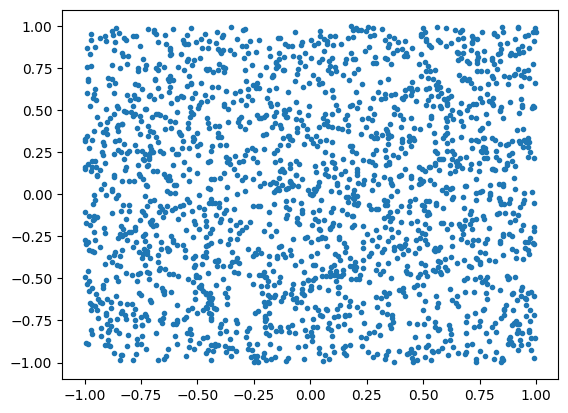

In [13]:
plt.plot(zsensors[:,0], zsensors[:,1],'.')

In [14]:
out = deeponet.apply(params, de_points, zsensors[:,:1], zsensors[:,1:])

In [19]:
# DeepONet training function (standard DeepONet)
@jax.jit
def train_step(params, pdes, z, zt):
  t = pdes[:,0]

  def u_model(t, z, zt, params):
    return deeponet.apply(params, t, z, zt)[0]
  def u_t(t, z, zt, params):
    return jax.vmap(jax.grad(u_model, 0), [0, 0, 0, None])(t, z, zt, params)
  def u_tt(t, z, zt, params):
    return jax.vmap(jax.grad(jax.grad(u_model,0), 0), [0, 0, 0, None])(t, z, zt, params)

  def loss(params, t, z, zt):

    term1 = u_tt(t, z, zt, params)
    print(term1.shape)
    input()
    term2 = jax.vmap(u_model, [0, 0, 0, None])(t, z, zt, params)

    eqn = term1 + term2

    return jnp.mean(eqn**2)

  return jax.value_and_grad(loss)(params, t, z, zt)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [20]:
def train_network(params, des, zsensor, epochs=100):

  # Number of ICs and total number of DE collocation points
  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  lr = 1e-3
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensors)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.zeros(epochs)

  for i in range(epochs):

    for (des_batch, z_batch) in ds:

      z0 = z_batch[:,:1].numpy()
      zt0 = z_batch[:,1:2].numpy()

      loss, grads = train_step(params, des_batch.numpy(), z0, zt0)
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 100 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [ ]:
epochs = 500
params, loss = train_network(params, de_points, zsensors, epochs)

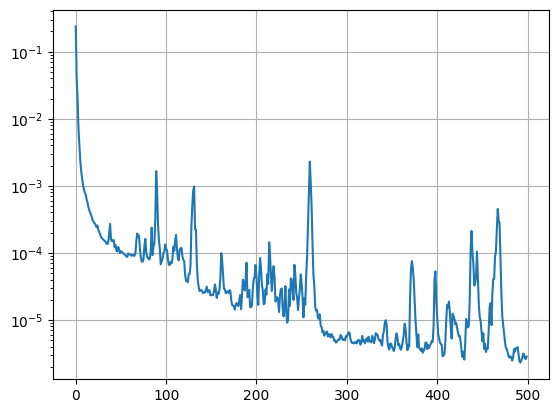

In [18]:
plt.semilogy(loss)
plt.grid()

In [ ]:
# Grid where to evaluate the model
n = 200
t = np.linspace(t0, tfinal, n)

# Sample a new IC
init_data = np.random.uniform(-1.0, 1.0, size=(2,))
z = np.repeat(np.expand_dims(init_data, axis=0), len(t), axis=0)

# Model prediction
u = deeponet.apply(params, t, z[:,:1], z[:,1:])

In [ ]:
def ho(y, t):
  x, xt = y
  dydt = [xt, -x]
  return dydt

sol_rk = odeint(ho, init_data, t)

Text(0, 0.5, 'u')

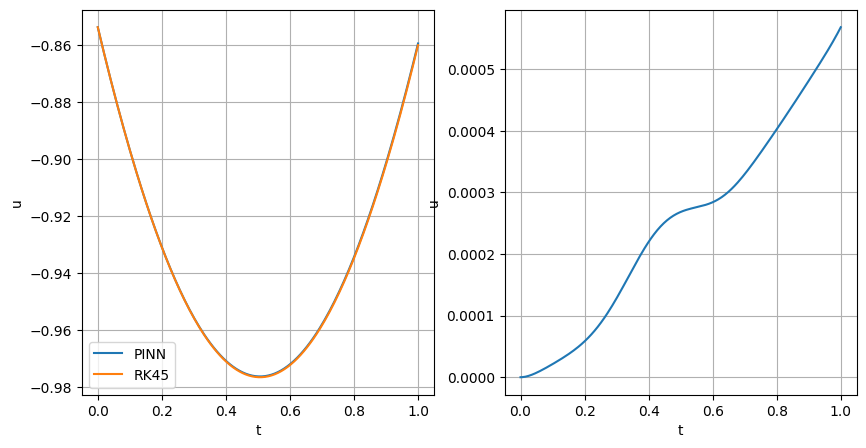

In [ ]:
fig = plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.plot(t, u)
plt.plot(t, sol_rk[:,0])
plt.legend(['PINN', 'RK45'])
plt.grid()
plt.xlabel('t')
plt.ylabel('u')

plt.subplot(122)
plt.plot(t, u-sol_rk[:,0])
plt.grid()
plt.xlabel('t')
plt.ylabel('u')

### Time stepping

In [ ]:
steps = 100
tfinalsteps = tfinal*steps
tt = np.linspace(0, tfinalsteps, (n-1)*steps)

In [ ]:
@jax.jit
def u_model(t, z, zt, params):
  return deeponet.apply(params, t, z, zt)[0]

@jax.jit
def u_t(t, z, zt, params):
  return jax.vmap(jax.grad(u_model, 0), [0, 0, 0, None])(t, z, zt, params)

In [ ]:
# Non-conservative method
zinit = init_data

zall = []

for i in range(steps):
  zinit = np.repeat(np.expand_dims(zinit, axis=0), len(t), axis=0)

  u = deeponet.apply(params, t, zinit[:,:1], zinit[:,1:])
  ut = u_t(t, zinit[:,:1], zinit[:,1:], params)

  zinit = np.array([u[-1], ut[-1]])
  zall.append(u[:-1])

uall = np.concatenate(zall, axis=0)

In [ ]:
# RK reference solution
sol_rk_all = odeint(ho, init_data, tt)

Text(0, 0.5, 'error')

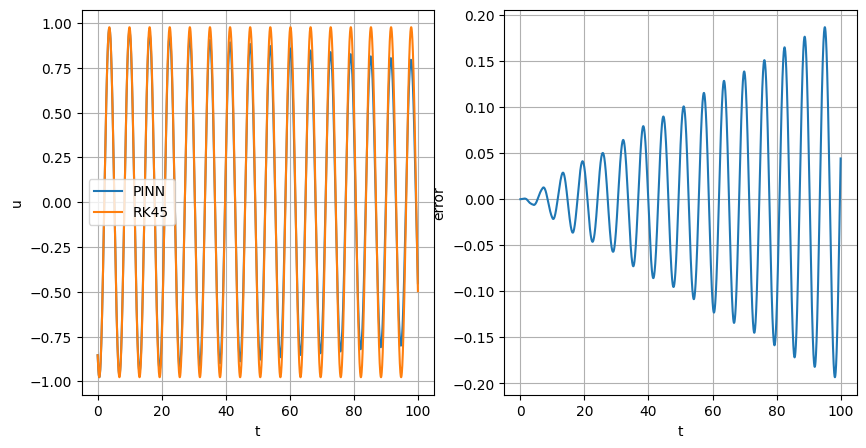

In [ ]:
fig = plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.plot(tt, uall)
plt.plot(tt, sol_rk_all[:,0])
plt.legend(['PINN', 'RK45'])
plt.grid()
plt.xlabel('t')
plt.ylabel('u')

plt.subplot(122)
plt.plot(tt, uall-sol_rk_all[:,0])
plt.grid()
plt.xlabel('t')
plt.ylabel('error')